# Does the pooled score carry over?

The pooled weights from `multi_pair_models.ipynb` were fitted on 24–50 fresh pairs per setting, all at one budget per setting (the training budget). This notebook asks how well the score ranks seed sets outside the data it was fitted on:

| Part | Question | Pairs | Budget |
|---|---|---|---|
| A (plan 1) | Does success still rise with the score on pairs the score never saw? | Round 1's 20 per setting | The training budget |
| B (plan 2) | Does it still work at other budgets? | Round 1's pairs 0–9 | Training budget − 2 and + 2 seeds (percolation) or − 3 and + 3 (GOAT, FAQ) |
| C (plan 2) | Does it still work for other sizes and sparsities of the same graph model? | 10 fresh pairs per grid cell | Calibrated so random sets succeed about half the time |

**Part C's grid.** Graph size by mean degree, for each graph model, with everything else as in round 1 (the model's shape, ρ and the solver settings):

| | 300 vertices | 600 vertices | 1,200 vertices |
|---|---|---|---|
| Mean degree × 0.75 | all | all | percolation |
| Mean degree × 1 | all | round 1's setting (part A) | percolation; GOAT and FAQ on Chung–Lu |
| Mean degree × 1.5 | all | all | percolation |

Round 1's mean degree is 12 for percolation and 16 for GOAT and FAQ. GOAT and FAQ runs are several times slower at 1,200 vertices, so only Chung–Lu (where hubs grow with size) gets that size for them.

**Seed sets.** On each pair and budget, 20,000 random seed sets are drawn and scored from graph A with the pooled weights. The weights are the base setting's, never refitted. These sets are run:
- **Random:** 60 sets in part A, 36 in B and C. These are the first sets drawn, so they are an unselected sample.
- **Tail:** 40 sets in part A, 24 in B and C, from the top 5% by score. They are spread over three bands: the top 0.1% (including the best set), 99–99.9% and 95–99%. Best of 100 picks around the 99th percentile and best of 1,000 around the 99.9th.
- **Round 1's rules (part A only):** their sets at the training budget, placed on the same score.

Each set is run once with round 1's solver settings (FAQ once, as in the training data).

**Run time:** about 12 hours with 3 jobs. Part A takes about 3.5 hours, B about 2 and C about 6.5. To split it, run `PARTS_TO_RUN = ['A', 'B']` one night and `['C']` another. Each pair is saved when it finishes, and rerunning resumes. The analysis sections work on whatever is finished.

| Section | Content |
|---|---|
| 1 | Checks and part C's budgets |
| 2 | Part A: new pairs at the training budget, including best of N up to N = 20,000 |
| 3 | Part B: other budgets |
| 4 | Part C: other sizes and sparsities |
| 5 | Ranking at the training setting and other budgets (AUC) |
| 6 | GOAT runs that stall |

In [15]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
if str(EXPERIMENT_DIR.parent) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR.parent))

import importlib

from selection_rule_comparison.archive import score_transfer as ST

ST = importlib.reload(ST)   # picks up edits to score_transfer.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.max_colwidth', 120)

RUN_COLLECTION = True                                 # False: only analyse saved results
PARTS_TO_RUN = ['C']                        # run in this order; remove any to skip it
ALGORITHMS_TO_RUN = ['percolation']    # remove any to skip it
JOBS = 3                                              # tasks run in parallel

## Run

The cell below prints an estimate per part, then one line per finished task. In part C, each change starts with a budget calibration. Its line reports the budget chosen and the random success rate at every budget tried. The change's 10 pairs follow.

The interrupt button stops the workers too. To run in a terminal instead, from the repository root: `python -m selection_rule_comparison.score_transfer`. Ctrl-C stops it, and `--status` shows how far it is. Then set `RUN_COLLECTION = False` here to analyse.

In [16]:
if RUN_COLLECTION:
    ST.run_all(PARTS_TO_RUN, ALGORITHMS_TO_RUN, jobs=JOBS)
display(ST.status())

Tue 00:29  Part C: 105 tasks, about 80 min
Tue 00:29  About 1.3 hours in all with 3 jobs (part C's budgets are calibrated first, so its time is a guess). Each line below is one finished task.
Tue 00:29  [1/105] C · Percolation ER 300 vertices, degree x0.75 · pair 1 · k = 7: 60 runs in 0.1 min; about 80 min left
Tue 00:29  [2/105] C · Percolation ER 300 vertices, degree x0.75 · pair 2 · k = 7: 60 runs in 0.1 min; about 80 min left
Tue 00:29  [3/105] C · Percolation ER 300 vertices, degree x0.75 · pair 0 · k = 7: 60 runs in 0.1 min; about 80 min left
Tue 00:29  [4/105] C · Percolation ER 300 vertices, degree x0.75 · pair 3 · k = 7: 60 runs in 0.1 min; about 80 min left
Tue 00:29  [5/105] C · Percolation ER 300 vertices, degree x0.75 · pair 4 · k = 7: 60 runs in 0.1 min; about 80 min left
Tue 00:29  [6/105] C · Percolation ER 300 vertices, degree x0.75 · pair 5 · k = 7: 60 runs in 0.1 min; about 80 min left
Tue 00:29  [7/105] C · Percolation ER 300 vertices, degree x0.75 · pair 6 · k = 7:

pairs planned  \
part algorithm   model    condition                                                              
A    Percolation ER       training budget, k = 8                                            20   
B    Percolation ER       k0-2, k = 6                                                       10   
                          k0+2, k = 10                                                      10   
C    Percolation ER       300 vertices, degree x0.75, k = 7                                 10   
                          300 vertices, degree x1, k = 6                                    10   
                          300 vertices, degree x1.5, k = 6                                  10   
                          600 vertices, degree x0.75, k = 12                                10   
                          600 vertices, degree x1.5, k = 7                                  10   
                          1,200 vertices, degree x0.75, k = 17                              10   
                          1,200 vertices, degree x1, k = 10                                 10   
                          1,200 vertices, degree x1.5, k = 6                                10   
A    Percolation PAPER    training budget, k = 7                                            20   
B    Percolation PAPER    k0-2, k = 5                                                       10   
                          k0+2, k = 9                                                       10   
C    Percolation PAPER    300 vertices, degree x0.75, k = 6                                 10   
                          300 vertices, degree x1, k = 6                                    10   
                          300 vertices, degree x1.5, k = 6                                  10   
                          600 vertices, degree x0.75, k = 8                                 10   
                          600 vertices, degree x1.5, k = 7                                  10   
                          1,200 vertices, degree x0.75, k = 4                               10   
                          1,200 vertices, degree x1, k = 8                                  10   
                          1,200 vertices, degree x1.5, k = 7                                10   
A    Percolation Chung-Lu training budget, k = 5                                            20   
B    Percolation Chung-Lu k0-2, k = 3                                                       10   
                          k0+2, k = 7                                                       10   
C    Percolation Chung-Lu 300 vertices, degree x0.75, k = 6                                 10   
                          300 vertices, degree x1, k = 4                                    10   
                          300 vertices, degree x1.5, k = 3                                  10   
                          600 vertices, degree x0.75, k = 7                                 10   
                          600 vertices, degree x1.5, k = 3                                  10   
                          1,200 vertices, degree x0.75, k = 6                               10   
                          1,200 vertices, degree x1, k = 5                                  10   
                          1,200 vertices, degree x1.5, k = 5                                10   
A    GOAT        ER       training budget, k = 15                                           20   
B    GOAT        ER       k0-3, k = 12                                                      10   
                          k0+3, k = 18                                                      10   
C    GOAT        ER       300 vertices, degree x0.75, k = 14                                10   
                          300 vertices, degree x1, k = 12                                   10   
                          300 vertices, degree x1.5, k = 8                                  10   
                          600 vertices, degree x0.75: budget no

## 1. Checks and part C's budgets

- **Pairs.** Round 1's pairs (parts A and B) were regenerated and matched round 1's stored hashes. Round 1's rule sets were regenerated from round 1's random streams and matched its stored orderings. Any mismatch stops the run.
- **Sets per condition.** The random sets' mean percentile should be near 50: they are a random sample of the pool. Every tail set should be at the 95th percentile or above.
- **Part C's budgets.** For each grid cell, the budget where random sets succeed about half the time, found from 30 random sets per budget tried (3 on each of the 10 pairs). If no random set succeeds even at the top of the ladder, the cell is skipped and marked so.

In [17]:
data = ST.read_sets()
display(ST.check_table(data))
calibration = ST.calibration_table()
if calibration.empty:
    print('No part C calibration yet.')
else:
    display(calibration)

budget  pairs  random sets  tail sets  \
part algorithm   model    condition                                            
A    Percolation ER       training          8     20         1200        800   
                 PAPER    training          7     20         1200        800   
                 Chung-Lu training          5     20         1200        800   
     GOAT        ER       training         15     20         1200        800   
                 PAPER    training         12     20         1200        800   
                 Chung-Lu training          9     20         1200        800   
     SGM (FAQ)   ER       training         29     20         1200        800   
                 PAPER    training         29     20         1200        800   
                 Chung-Lu training         27     20         1200        800   
B    Percolation ER       k0-2              6     10          360        240   
                          k0+2             10     10          360        240   
                 PAPER    k0-2              5     10          360        240   
                          k0+2              9     10          360        240   
                 Chung-Lu k0-2              3     10          360        240   
                          k0+2              7     10          360        240   
     GOAT        ER       k0-3             12     10          360        240   
                          k0+3             18     10          360        240   
                 PAPER    k0-3              9     10          360        240   
                          k0+3             15     10          360        240   
                 Chung-Lu k0-3              6     10          360        240   
                          k0+3             12     10          360        240   
     SGM (FAQ)   ER       k0-3             26     10          360        240   
                          k0+3             32     10          360        240   
                 PAPER    k0-3             26     10          360        240   
                          k0+3             32     10          360        240   
                 Chung-Lu k0-3             24     10          360        240   
                          k0+3             30     10          360        240   
C    Percolation ER       n300_x0.75        7     10          360        240   
                          n300_x1           6     10          360        240   
                          n300_x1.5         6     10          360        240   
                          n600_x0.75       12     10          360        240   
                          n600_x1.5         7     10          360        240   
                          n1200_x0.75      17     10          360        240   
                          n1200_x1         10     10          360        240   
                          n1200_x1.5        6     10          360        240   
                 PAPER    n300_x0.75        6     10          360        240   
                          n300_x1           6     10          360        240   
                          n300_x1.5         6     10          360        240   
                          n600_x0.75        8     10          360        240   
                          n600_x1.5         7     10          360        240   
                          n1200_x0.75       4     10          360        240   
                          n1200_x1          8     10          360        240   
                          n1200_x1.5        7     10          360        240   
                 Chung-Lu n300_x0.75        6     10          360        240   
                          n300_x1           4     10          360        240   
                          n300_x1.5         3     10          360        240   
                          n600_x0.75        7     10          360        240   
                          n600_x1.5         3     10          360        240   
                          n1200_x0.75  

setting  \
algorithm   model    cell                                                   
Percolation ER       n300_x0.75     300 vertices, mean degree 9.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 12.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 18.0 (x1.5)   
                     n600_x0.75     600 vertices, mean degree 9.0 (x0.75)   
                     n600_x1.5      600 vertices, mean degree 18.0 (x1.5)   
                     n1200_x0.75  1,200 vertices, mean degree 9.0 (x0.75)   
                     n1200_x1       1,200 vertices, mean degree 12.0 (x1)   
                     n1200_x1.5   1,200 vertices, mean degree 18.0 (x1.5)   
            PAPER    n300_x0.75     300 vertices, mean degree 9.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 12.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 18.0 (x1.5)   
                     n600_x0.75     600 vertices, mean degree 9.0 (x0.75)   
                     n600_x1.5      600 vertices, mean degree 18.0 (x1.5)   
                     n1200_x0.75  1,200 vertices, mean degree 9.0 (x0.75)   
                     n1200_x1       1,200 vertices, mean degree 12.0 (x1)   
                     n1200_x1.5   1,200 vertices, mean degree 18.0 (x1.5)   
            Chung-Lu n300_x0.75     300 vertices, mean degree 9.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 12.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 18.0 (x1.5)   
                     n600_x0.75     600 vertices, mean degree 9.0 (x0.75)   
                     n600_x1.5      600 vertices, mean degree 18.0 (x1.5)   
                     n1200_x0.75  1,200 vertices, mean degree 9.0 (x0.75)   
                     n1200_x1       1,200 vertices, mean degree 12.0 (x1)   
                     n1200_x1.5   1,200 vertices, mean degree 18.0 (x1.5)   
GOAT        ER       n300_x0.75    300 vertices, mean degree 12.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 16.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 24.0 (x1.5)   
            PAPER    n300_x0.75    300 vertices, mean degree 12.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 16.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 24.0 (x1.5)   
            Chung-Lu n300_x0.75    300 vertices, mean degree 12.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 16.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 24.0 (x1.5)   
SGM (FAQ)   ER       n300_x0.75    300 vertices, mean degree 12.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 16.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 24.0 (x1.5)   
            PAPER    n300_x0.75    300 vertices, mean degree 12.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 16.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 24.0 (x1.5)   
            Chung-Lu n300_x0.75    300 vertices, mean degree 12.0 (x0.75)   
                     n300_x1          300 vertices, mean degree 16.0 (x1)   
                     n300_x1.5      300 vertices, mean degree 24.0 (x1.5)   

                                  training budget  budget used  \
algorithm   model    cell                                        
Percolation ER       n300_x0.75                 8            7   
                     n300_x1                    8            6   
                     n300_x1.5                  8            6   
                     n600_x0.75                 8           12   
                     n600_x1.5                  8            7   
                     n1200_x0.75                8           17   
                     n1200_x1                   8           10   
                     n1200_x1.5                 8            6   
            PAPER

## 2. Part A: new pairs at the training budget

### 2.1 Success by score percentile

Each panel shows round 1's 20 pairs at the setting's training budget.
- **Dark blue:** the success rate of the random and tail sets, binned by their score's percentile among the pair's 20,000 random sets.
- **Dashed grey:** the same curve on the multi-pair data, where each pair is scored by a model fitted without it (`multi_pair_models.ipynb`, section 3).
- **Dotted lines:** the average random set in each.

If the two curves agree, the score works as well on new pairs as cross-validation said. The rightmost two bins are where best of 100 and best of 1,000 pick.

The table gives the success rate of the random sets and of the tail sets in each band, with pair-by-pair differences. The intervals are 95% bootstrap intervals over pairs.

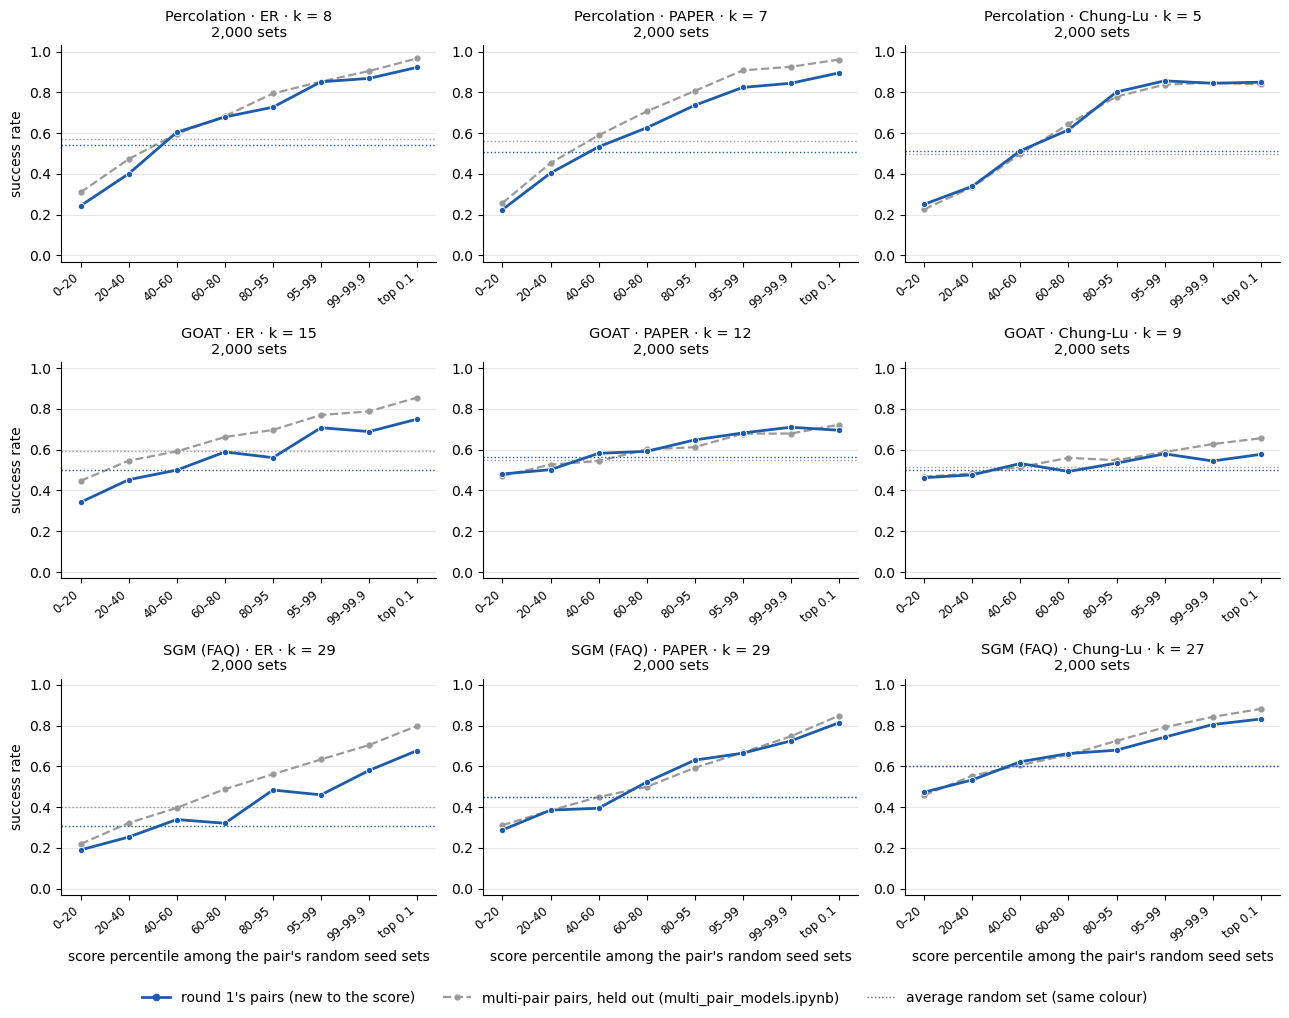

pairs             random  \
algorithm   model    condition budget                             
Percolation ER       training  8          20  0.54 [0.51, 0.57]   
            PAPER    training  7          20  0.51 [0.46, 0.55]   
            Chung-Lu training  5          20  0.51 [0.46, 0.56]   
GOAT        ER       training  15         20  0.50 [0.43, 0.58]   
            PAPER    training  12         20  0.57 [0.45, 0.68]   
            Chung-Lu training  9          20  0.50 [0.41, 0.59]   
SGM (FAQ)   ER       training  29         20  0.31 [0.24, 0.39]   
            PAPER    training  29         20  0.45 [0.37, 0.53]   
            Chung-Lu training  27         20  0.60 [0.53, 0.67]   

                                              tail 95-99  \
algorithm   model    condition budget                      
Percolation ER       training  8       0.85 [0.81, 0.89]   
            PAPER    training  7       0.82 [0.73, 0.90]   
            Chung-Lu training  5       0.85 [0.80, 0.90]   
GOAT        ER       training  15      0.68 [0.62, 0.74]   
            PAPER    training  12      0.68 [0.57, 0.78]   
            Chung-Lu training  9       0.59 [0.49, 0.67]   
SGM (FAQ)   ER       training  29      0.48 [0.39, 0.58]   
            PAPER    training  29      0.67 [0.58, 0.74]   
            Chung-Lu training  27      0.74 [0.66, 0.82]   

                                        tail 95-99 - random  \
algorithm   model    condition budget                         
Percolation ER       training  8       +0.31 [+0.26, +0.36]   
            PAPER    training  7       +0.32 [+0.24, +0.38]   
            Chung-Lu training  5       +0.34 [+0.29, +0.38]   
GOAT        ER       training  15      +0.18 [+0.12, +0.24]   
            PAPER    training  12      +0.11 [+0.07, +0.16]   
            Chung-Lu training  9       +0.09 [+0.03, +0.14]   
SGM (FAQ)   ER       training  29      +0.17 [+0.11, +0.22]   
            PAPER    training  29      +0.22 [+0.16, +0.27]   
            Chung-Lu training  27      +0.14 [+0.09, +0.19]   

                                            tail 99-99.9  \
algorithm   model    condition budget                      
Percolation ER       training  8       0.85 [0.81, 0.89]   
            PAPER    training  7       0.86 [0.79, 0.92]   
            Chung-Lu training  5       0.85 [0.78, 0.91]   
GOAT        ER       training  15      0.72 [0.65, 0.79]   
            PAPER    training  12      0.70 [0.60, 0.81]   
            Chung-Lu training  9       0.54 [0.43, 0.64]   
SGM (FAQ)   ER       training  29      0.59 [0.50, 0.67]   
            PAPER    training  29      0.74 [0.63, 0.83]   
            Chung-Lu training  27      0.81 [0.72, 0.88]   

                                      tail 99-99.9 - random  \
algorithm   model    condition budget                         
Percolation ER       training  8       +0.31 [+0.26, +0.37]   
            PAPER    training  7       +0.35 [+0.30, +0.41]   
            Chung-Lu training  5       +0.34 [+0.26, +0.41]   
GOAT        ER       training  15      +0.22 [+0.16, +0.28]   
            PAPER    training  12      +0.14 [+0.09, +0.19]   
            Chung-Lu training  9       +0.04 [-0.03, +0.11]   
SGM (FAQ)   ER       training  29      +0.28 [+0.20, +0.35]   
            PAPER    training  29      +0.29 [+0.23, +0.34]   
            Chung-Lu training  27      +0.21 [+0.16, +0.25]   

                                            tail top 0.1 tail top 0.1 - random  
algorithm   model    condition budget                                           
Percolation ER       training  8       0.93 [0.90, 0.96]  +0.39 [+0.35, +0.44]  
            PAPER    training  7       0.89 [0.79, 0.97]  +0.38 [+0.29, +0.47]  
            Chung-Lu training  5       0.85 [0.79, 0.90]  +0.34 [+0.30, +0.38]  
GOAT        ER       training  15      0.75 [0.68, 0.82]  +0.25 [+0.20, +0.30]  
            PAPER    training  12      0.70 [0.59, 0.80]  +0.14 [+0.08, +0.19]  
            Chung-Lu tra

In [18]:
reference_curves, reference_auc = ST.reference_tables()
curves = ST.percentile_curves(data)
if (curves['part'] == 'A').any():
    ST.plot_transfer(curves, reference_curves)
    plt.show()
    lifts = ST.lift_table(data)
    display(lifts.xs('A', level='part'))
else:
    print('Part A has no results yet.')

### 2.2 Success against the raw score, with round 1's rules

The x-axis is now the score itself, in SDs of random sets; 0 is the average random set.
- **Blue:** random and tail sets in eight equal-count score bins, with 95% intervals over pairs. The grey band is the score range these sets cover.
- **Black square and orange markers:** round 1's rules at the same budget: top degree in black, the others in orange with one shape each (see the legend). Each rule has one set per pair. The marker shows the rule's mean score and its success rate over the 20 pairs, with a 95% interval.

Round 1's rules mostly sit far to the right of the band. Their scores are extrapolations: the weights were never fitted on sets like them. A rule above the blue trend does better than the score predicts, and a rule below it does worse.

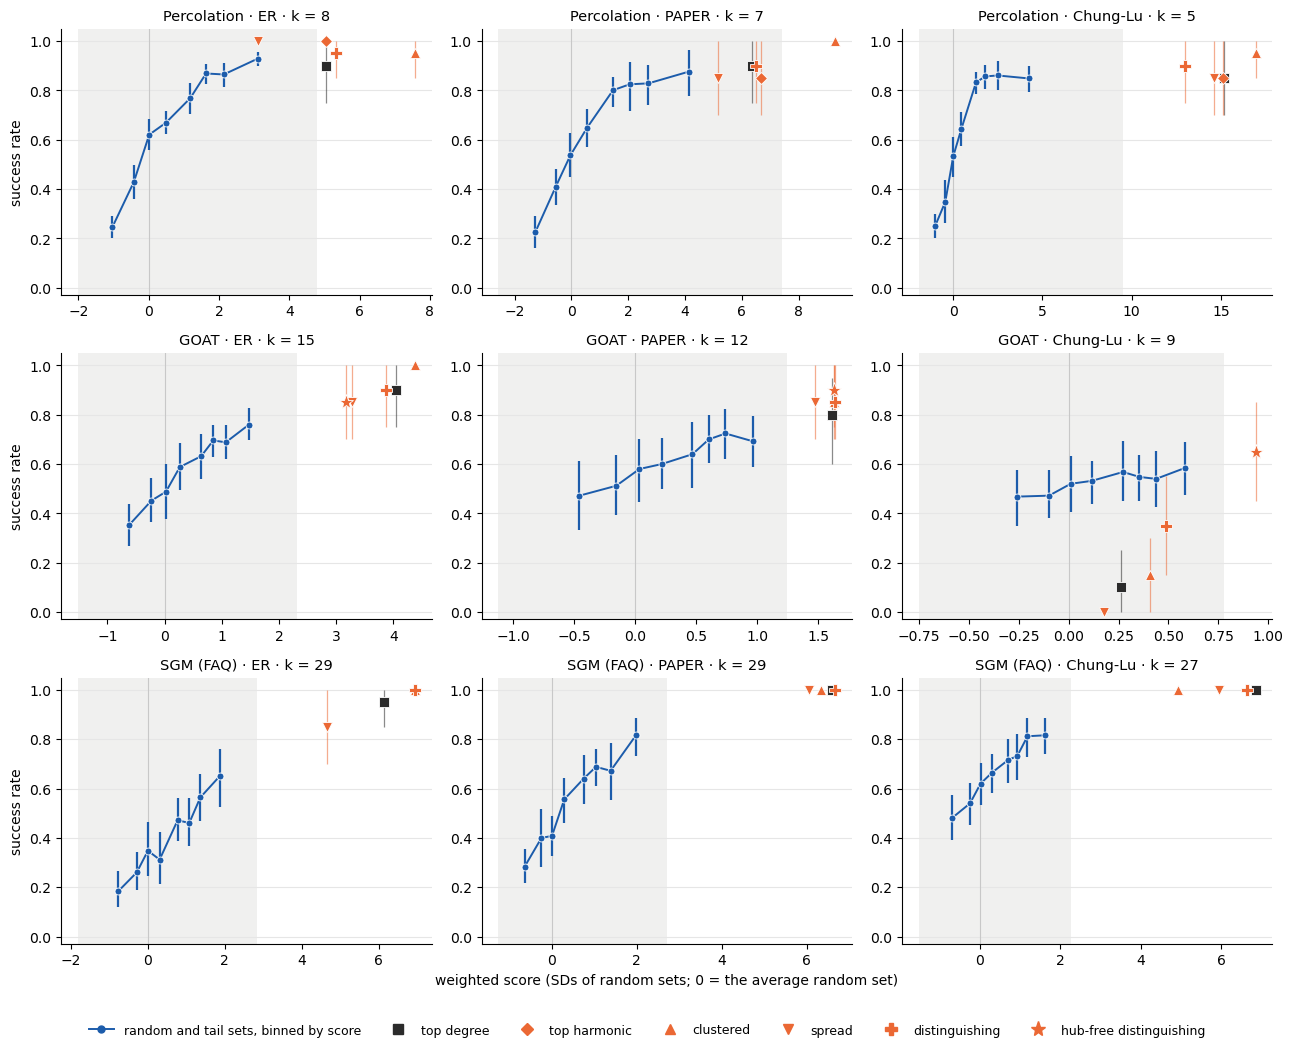

pairs  score  median percentile  \
algorithm   model    rule                                                       
Percolation ER       top degree                  20   5.04             100.00   
                     top harmonic                20   5.04             100.00   
                     clustered                   20   7.58             100.00   
                     spread                      20   3.10              99.96   
                     distinguishing              20   5.34             100.00   
            PAPER    top degree                  20   6.35             100.00   
                     top harmonic                20   6.66             100.00   
                     clustered                   20   9.30             100.00   
                     spread                      20   5.15             100.00   
                     distinguishing              20   6.50             100.00   
            Chung-Lu top degree                  20  15.19             100.00   
                     top harmonic                20  15.14             100.00   
                     clustered                   20  16.95             100.00   
                     spread                      20  14.63             100.00   
                     distinguishing              20  12.99             100.00   
GOAT        ER       top degree                  20   4.04             100.00   
                     clustered                   20   4.38             100.00   
                     spread                      20   3.27             100.00   
                     distinguishing              20   3.88             100.00   
                     hub-free distinguishing     20   3.17             100.00   
            PAPER    top degree                  20   1.62             100.00   
                     clustered                   20   1.63             100.00   
                     spread                      20   1.48             100.00   
                     distinguishing              20   1.64             100.00   
                     hub-free distinguishing     20   1.63             100.00   
            Chung-Lu top degree                  20   0.26              91.83   
                     clustered                   20   0.41              98.47   
                     spread                      20   0.18              81.29   
                     distinguishing              20   0.49              99.80   
                     hub-free distinguishing     20   0.94             100.00   
SGM (FAQ)   ER       top degree                  20   6.13             100.00   
                     clustered                   20   6.94             100.00   
                     spread                      20   4.65             100.00   
                     distinguishing              20   6.95             100.00   
            PAPER    top degree                  20   6.59             100.00   
                     clustered                   20   6.33             100.00   
                     spread                      20   6.06             100.00   
                     distinguishing              20   6.67             100.00   
            Chung-Lu top degree                  20   6.86             100.00   
                     clustered                   20   4.93             100.00   
                     spread                      20   5.94             100.00   
                     distinguishing              20   6.64             100.00   

                                              z degree  success   low  high  
algorithm   model    rule                                                    
Percolation ER       top degree                   7.89     0.90  0.75  1.00  
                     top harmonic                 7.39     1.00  1.00  1.00  
                     clustered                    7.29     0.95  0.85  1.00  
                     spread                       7.74     1.00  1.00  1.00  
             

In [19]:
if (data['part'] == 'A').any():
    binned = ST.binned_by_score(data)
    rules = ST.rule_points(data)
    ST.plot_raw_score(binned, rules)
    plt.show()
    shown = rules.assign(algorithm=rules['algorithm'].map(ST.ALGORITHM_LABELS),
                         model=rules['model'].map(ST.MODEL_LABELS),
                         rule=rules['rule'].map(lambda r: ST.RULE_LABELS.get(r, r)))
    display(shown.set_index(['algorithm', 'model', 'rule'])[
        ['pairs', 'score', 'median percentile', 'z degree', 'success', 'low', 'high']].round(2))

### 2.3 Ranking within pairs

These measures use the random sets only.
- **AUC:** within each pair, the chance that a successful random set scores higher than a failed one. It is averaged over pairs where random sets both succeed and fail; 0.5 is chance. The score is compared with degree alone (seed-to-nonseed edges).
- **Top fifth:** the success rate of the 20% of each pair's random sets that rank highest by the score, and by degree alone.

In [20]:
ranking = ST.ranking_table(data)
if (ranking['part'] == 'A').any():
    display(ST.show_ranking(ranking[ranking['part'] == 'A']).droplevel('part'))

random success  \
algorithm   model    condition budget                   
Percolation ER       training  8                 0.54   
            PAPER    training  7                 0.51   
            Chung-Lu training  5                 0.51   
GOAT        ER       training  15                0.50   
            PAPER    training  12                0.56   
            Chung-Lu training  9                 0.50   
SGM (FAQ)   ER       training  29                0.31   
            PAPER    training  29                0.45   
            Chung-Lu training  27                0.60   

                                       pairs with both outcomes  \
algorithm   model    condition budget                             
Percolation ER       training  8                             20   
            PAPER    training  7                             20   
            Chung-Lu training  5                             20   
GOAT        ER       training  15                            20   
            PAPER    training  12                            20   
            Chung-Lu training  9                             20   
SGM (FAQ)   ER       training  29                            20   
            PAPER    training  29                            20   
            Chung-Lu training  27                            20   

                                               AUC score         AUC degree  \
algorithm   model    condition budget                                         
Percolation ER       training  8       0.73 [0.70, 0.75]  0.66 [0.63, 0.69]   
            PAPER    training  7       0.73 [0.69, 0.77]  0.63 [0.60, 0.67]   
            Chung-Lu training  5       0.74 [0.71, 0.76]  0.66 [0.62, 0.70]   
GOAT        ER       training  15      0.64 [0.61, 0.68]  0.65 [0.61, 0.68]   
            PAPER    training  12      0.60 [0.57, 0.63]  0.58 [0.54, 0.62]   
            Chung-Lu training  9       0.53 [0.50, 0.57]  0.52 [0.48, 0.56]   
SGM (FAQ)   ER       training  29      0.64 [0.60, 0.68]  0.64 [0.61, 0.68]   
            PAPER    training  29      0.65 [0.62, 0.67]  0.65 [0.63, 0.67]   
            Chung-Lu training  27      0.62 [0.58, 0.65]  0.57 [0.53, 0.61]   

                                         AUC score - degree  \
algorithm   model    condition budget                         
Percolation ER       training  8       +0.07 [+0.04, +0.09]   
            PAPER    training  7       +0.10 [+0.07, +0.13]   
            Chung-Lu training  5       +0.08 [+0.05, +0.11]   
GOAT        ER       training  15      -0.00 [-0.01, +0.01]   
            PAPER    training  12      +0.02 [-0.02, +0.06]   
            Chung-Lu training  9       +0.01 [-0.02, +0.05]   
SGM (FAQ)   ER       training  29      -0.00 [-0.02, +0.02]   
            PAPER    training  29      -0.00 [-0.00, +0.00]   
            Chung-Lu training  27      +0.05 [+0.01, +0.09]   

                                      top fifth by score top fifth by degree  
algorithm   model    condition budget                                         
Percolation ER       training  8       0.77 [0.71, 0.83]   0.76 [0.68, 0.83]  
            PAPER    training  7       0.77 [0.69, 0.84]   0.61 [0.54, 0.68]  
            Chung-Lu training  5       0.79 [0.72, 0.85]   0.70 [0.64, 0.76]  
GOAT        ER       training  15      0.64 [0.55, 0.73]   0.65 [0.57, 0.75]  
            PAPER    training  12      0.68 [0.55, 0.79]   0.66 [0.53, 0.78]  
            Chung-Lu training  9       0.53 [0.41, 0.64]   0.50 [0.40, 0.60]  
SGM (FAQ)   ER       training  29      0.45 [0.36, 0.55]   0.40 [0.32, 0.48]  
            PAPER    training  29      0.63 [0.54, 0.72]   0.63 [0.53, 0.72]  
            Chung-Lu training  27      0.70 [0.60, 0.78]   0.69 [0.60, 0.77]

### 2.4 Best of N, for N from 1 to 20,000

Each pair's 20,000 random sets were ranked by score. The set ranked r-th is about what best of N = 20,000 / r would pick: the best of N random sets sits near the top 1/N of the scores. The 40 high-scoring sets per pair therefore trace best of N from N = 20 (rank about 1,000) up to N = 20,000 (the pair's best set). N = 1 is the random sets.
- **Blue:** the success rate in each range of N, pooled over pairs. The intervals are 95% intervals from resampling whole pairs.
- **Dashed lines:** top degree and round 1's best rule at the same budget, on the same pairs.
- **Grey band:** best of 100 to best of 1,000, the range tested in `best_of_n.ipynb`.

If the curve keeps rising past N = 1,000, screening more sets still helps. If it flattens below top degree, no amount of screening random sets reaches it.

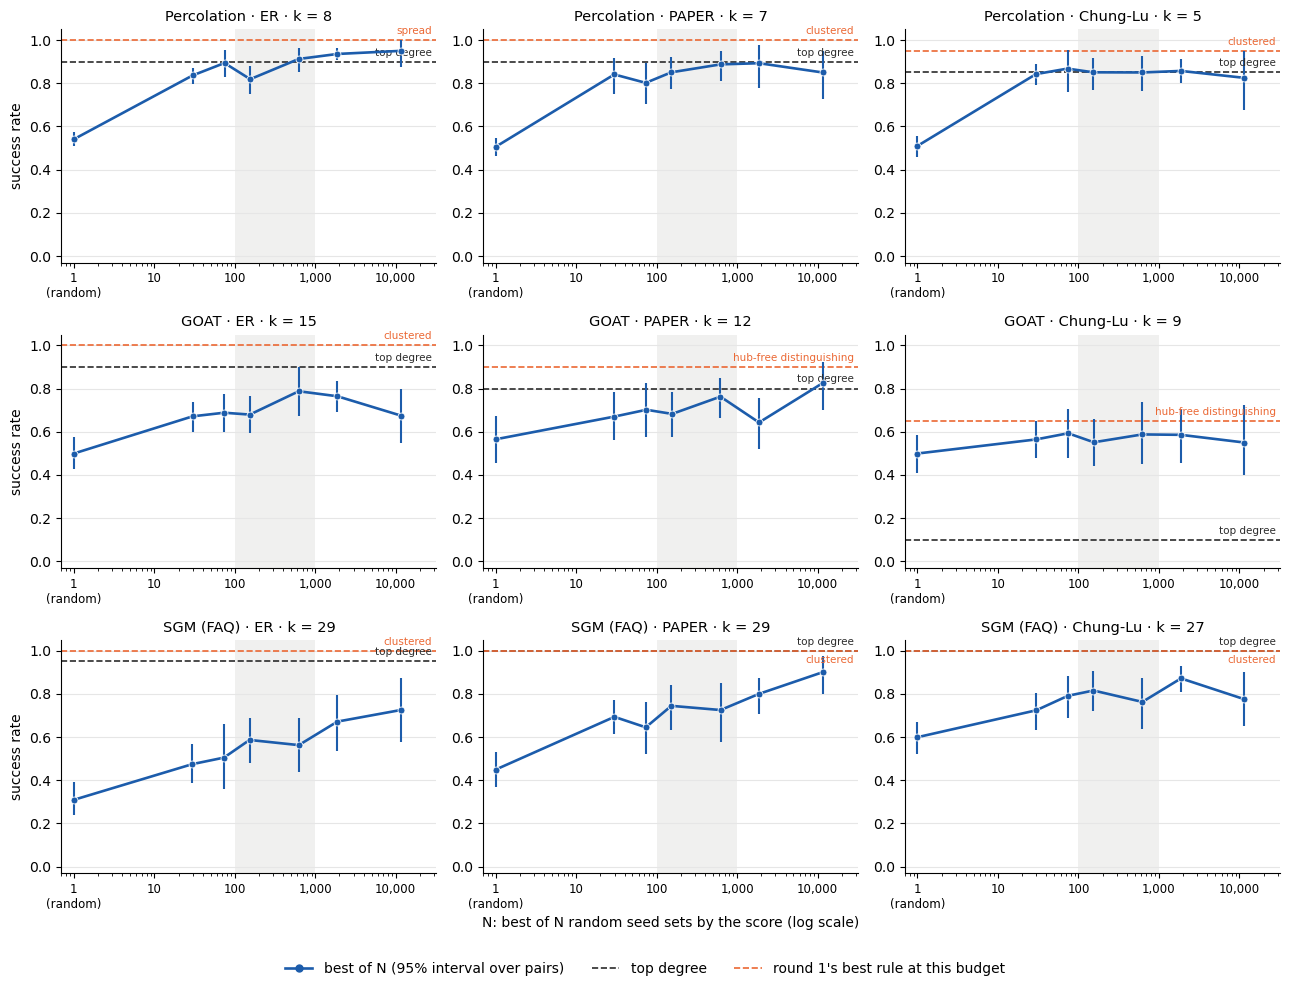

sets  pairs  success   low  high
algorithm   model    budget N                                             
Percolation ER       8      1 (random)    1200     20     0.54  0.51  0.57
                            20-50          287     20     0.84  0.80  0.87
                            50-100         113     20     0.89  0.83  0.96
                            100-300        127     20     0.82  0.75  0.88
                            300-1,000       80     20     0.91  0.85  0.96
                            1,000-5,000    140     20     0.94  0.91  0.96
                            5,000-20,000    40     20     0.95  0.88  1.00
            PAPER    7      1 (random)    1200     20     0.51  0.46  0.55
                            20-50          289     20     0.84  0.75  0.92
                            50-100         106     20     0.80  0.70  0.89
                            100-300        134     20     0.85  0.77  0.92
                            300-1,000       80     20     0.89  0.81  0.95
                            1,000-5,000    140     20     0.89  0.78  0.98
                            5,000-20,000    40     20     0.85  0.72  0.95
            Chung-Lu 5      1 (random)    1200     20     0.51  0.46  0.56
                            20-50          292     20     0.84  0.79  0.89
                            50-100         106     20     0.87  0.76  0.95
                            100-300        134     20     0.85  0.77  0.92
                            300-1,000       80     20     0.85  0.76  0.92
                            1,000-5,000    140     20     0.86  0.80  0.91
                            5,000-20,000    40     20     0.82  0.68  0.95
GOAT        ER       15     1 (random)    1200     20     0.50  0.43  0.57
                            20-50          286     20     0.67  0.60  0.74
                            50-100         109     20     0.69  0.60  0.77
                            100-300        131     20     0.68  0.59  0.77
                            300-1,000       80     20     0.79  0.67  0.90
                            1,000-5,000    140     20     0.76  0.69  0.84
                            5,000-20,000    40     20     0.68  0.55  0.80
            PAPER    12     1 (random)    1200     20     0.56  0.46  0.67
                            20-50          288     20     0.67  0.56  0.78
                            50-100         114     20     0.70  0.58  0.82
                            100-300        126     20     0.68  0.58  0.79
                            300-1,000       80     20     0.76  0.66  0.85
                            1,000-5,000    140     20     0.64  0.52  0.76
                            5,000-20,000    40     20     0.82  0.70  0.92
            Chung-Lu 9      1 (random)    1200     20     0.50  0.41  0.59
                            20-50          287     20     0.56  0.48  0.65
                            50-100         113     20     0.59  0.48  0.70
                            100-300        127     20     0.55  0.44  0.66
                            300-1,000       80     20     0.59  0.45  0.74
                            1,000-5,000    140     20     0.59  0.46  0.71
                            5,000-20,000    40     20     0.55  0.40  0.72
SGM (FAQ)   ER       29     1 (random)    1200     20     0.31  0.24  0.39
                            20-50          293     20     0.47  0.39  0.57
                            50-100         107     20     0.50  0.36  0.66
                            100-300        133     20     0.59  0.48  0.69
                            300-1,000       80     20     0.56  0.44  0.69
                            1,000-5,000    140     20     0.67  0.54  0.79
                            5,000-20,000    40     20     0.72  0.57  0.88
            PAPER    29     1 (random)    1200     20     0.45  0.37  0.53
                            20-50          287     20     0.69  0.61  0.77
                            50-100         107     20     0.64  0.5

In [21]:
if (data['part'] == 'A').any():
    best_of_n = ST.best_of_n_table(data)
    ST.plot_best_of_n(best_of_n, rules)
    plt.show()
    display(best_of_n.assign(algorithm=best_of_n['algorithm'].map(ST.ALGORITHM_LABELS),
                             model=best_of_n['model'].map(ST.MODEL_LABELS)).set_index(
        ['algorithm', 'model', 'budget', 'N'])[['sets', 'pairs', 'success', 'low', 'high']].round(2))

## 3. Part B: other budgets

The weights were fitted at one budget. Here they score sets at a smaller and a larger budget on round 1's pairs 0–9. The features are still measured in SDs of random sets of the same size.
- **Lines:** light blue for fewer seeds, middle blue for the training budget (part A, all 20 pairs) and dark blue for more seeds.
- **Dotted lines:** each budget's average random set, in the same colour.

A curve that still rises from left to right means the score still ranks sets at that budget. The tables give the lift over random and the ranking measures.

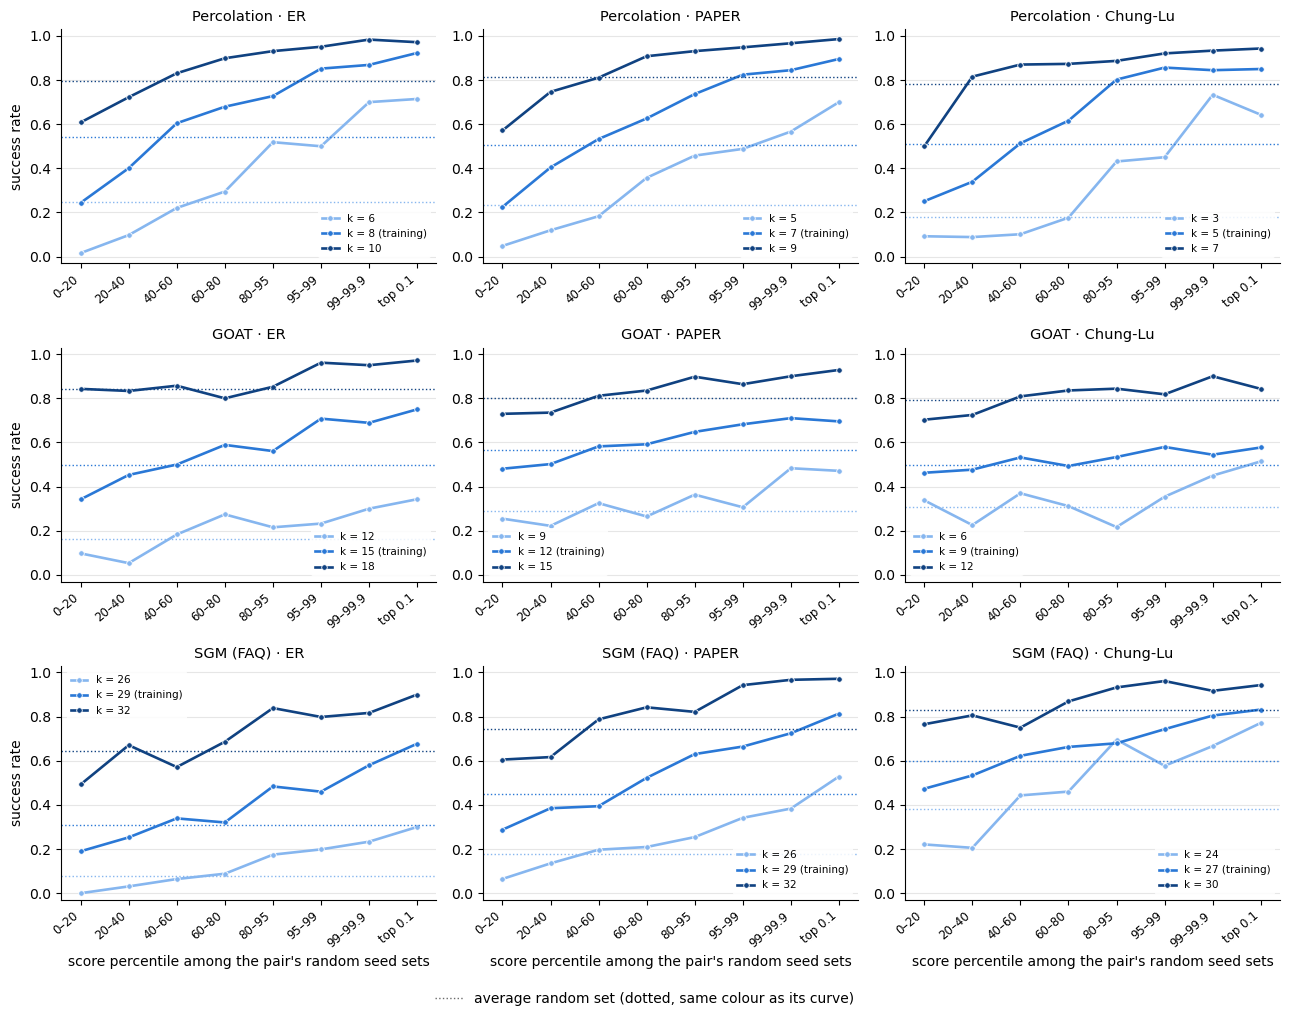

pairs             random  \
algorithm   model    condition budget                             
Percolation ER       k0-2      6          10  0.25 [0.20, 0.29]   
                     k0+2      10         10  0.80 [0.72, 0.86]   
            PAPER    k0-2      5          10  0.24 [0.18, 0.30]   
                     k0+2      9          10  0.81 [0.76, 0.87]   
            Chung-Lu k0-2      3          10  0.18 [0.13, 0.24]   
                     k0+2      7          10  0.78 [0.74, 0.82]   
GOAT        ER       k0-3      12         10  0.16 [0.09, 0.26]   
                     k0+3      18         10  0.84 [0.80, 0.89]   
            PAPER    k0-3      9          10  0.29 [0.16, 0.45]   
                     k0+3      15         10  0.80 [0.72, 0.88]   
            Chung-Lu k0-3      6          10  0.31 [0.20, 0.41]   
                     k0+3      12         10  0.79 [0.69, 0.89]   
SGM (FAQ)   ER       k0-3      26         10  0.08 [0.04, 0.12]   
                     k0+3      32         10  0.64 [0.56, 0.74]   
            PAPER    k0-3      26         10  0.18 [0.14, 0.22]   
                     k0+3      32         10  0.74 [0.64, 0.82]   
            Chung-Lu k0-3      24         10  0.38 [0.28, 0.48]   
                     k0+3      30         10  0.83 [0.75, 0.90]   

                                              tail 95-99  \
algorithm   model    condition budget                      
Percolation ER       k0-2      6       0.46 [0.38, 0.53]   
                     k0+2      10      0.96 [0.93, 0.98]   
            PAPER    k0-2      5       0.53 [0.42, 0.62]   
                     k0+2      9       0.93 [0.88, 0.98]   
            Chung-Lu k0-2      3       0.48 [0.35, 0.62]   
                     k0+2      7       0.93 [0.87, 0.98]   
GOAT        ER       k0-3      12      0.24 [0.15, 0.36]   
                     k0+3      18      0.96 [0.92, 0.99]   
            PAPER    k0-3      9       0.33 [0.17, 0.50]   
                     k0+3      15      0.85 [0.75, 0.94]   
            Chung-Lu k0-3      6       0.34 [0.23, 0.47]   
                     k0+3      12      0.81 [0.69, 0.91]   
SGM (FAQ)   ER       k0-3      26      0.20 [0.10, 0.33]   
                     k0+3      32      0.78 [0.70, 0.84]   
            PAPER    k0-3      26      0.33 [0.23, 0.44]   
                     k0+3      32      0.94 [0.85, 1.00]   
            Chung-Lu k0-3      24      0.59 [0.42, 0.75]   
                     k0+3      30      0.95 [0.92, 0.98]   

                                        tail 95-99 - random  \
algorithm   model    condition budget                         
Percolation ER       k0-2      6       +0.21 [+0.15, +0.27]   
                     k0+2      10      +0.16 [+0.10, +0.23]   
            PAPER    k0-2      5       +0.29 [+0.20, +0.37]   
                     k0+2      9       +0.12 [+0.06, +0.18]   
            Chung-Lu k0-2      3       +0.30 [+0.19, +0.42]   
                     k0+2      7       +0.15 [+0.08, +0.22]   
GOAT        ER       k0-3      12      +0.08 [+0.04, +0.13]   
                     k0+3      18      +0.12 [+0.08, +0.16]   
            PAPER    k0-3      9       +0.03 [-0.04, +0.12]   
                     k0+3      15      +0.05 [-0.02, +0.12]   
            Chung-Lu k0-3      6       +0.04 [-0.04, +0.12]   
                     k0+3      12      +0.02 [-0.07, +0.11]   
SGM (FAQ)   ER       k0-3      26      +0.12 [+0.05, +0.21]   
                     k0+3      32      +0.13 [+0.05, +0.21]   
            PAPER    k0-3      26      +0.16 [+0.05, +0.25]   
                     k0+3      32      +0.20 [+0.09, +0.32]   
            Chung-Lu k0-3      24      +0.21 [+0.11, +0.30]   
                     k0+3      30      +0.12 [+0.06, +0.18]   

                                            tail 99-99.9  \
algorithm   model    condition budget                      
Percolation ER       k0-2      6       0.68 [0.57, 0.78]   
                     k0+2      10      0.98 [0.95, 1.00]

random success  \
algorithm   model    condition budget                   
Percolation ER       k0-2      6                 0.25   
                     k0+2      10                0.80   
            PAPER    k0-2      5                 0.24   
                     k0+2      9                 0.81   
            Chung-Lu k0-2      3                 0.18   
                     k0+2      7                 0.78   
GOAT        ER       k0-3      12                0.16   
                     k0+3      18                0.84   
            PAPER    k0-3      9                 0.29   
                     k0+3      15                0.80   
            Chung-Lu k0-3      6                 0.31   
                     k0+3      12                0.79   
SGM (FAQ)   ER       k0-3      26                0.08   
                     k0+3      32                0.64   
            PAPER    k0-3      26                0.18   
                     k0+3      32                0.74   
            Chung-Lu k0-3      24                0.38   
                     k0+3      30                0.83   

                                       pairs with both outcomes  \
algorithm   model    condition budget                             
Percolation ER       k0-2      6                             10   
                     k0+2      10                            10   
            PAPER    k0-2      5                             10   
                     k0+2      9                             10   
            Chung-Lu k0-2      3                             10   
                     k0+2      7                             10   
GOAT        ER       k0-3      12                            10   
                     k0+3      18                            10   
            PAPER    k0-3      9                              9   
                     k0+3      15                            10   
            Chung-Lu k0-3      6                             10   
                     k0+3      12                            10   
SGM (FAQ)   ER       k0-3      26                             8   
                     k0+3      32                            10   
            PAPER    k0-3      26                            10   
                     k0+3      32                            10   
            Chung-Lu k0-3      24                            10   
                     k0+3      30                             9   

                                               AUC score         AUC degree  \
algorithm   model    condition budget                                         
Percolation ER       k0-2      6       0.79 [0.74, 0.85]  0.67 [0.60, 0.74]   
                     k0+2      10      0.73 [0.67, 0.80]  0.60 [0.52, 0.68]   
            PAPER    k0-2      5       0.73 [0.67, 0.80]  0.63 [0.57, 0.69]   
                     k0+2      9       0.77 [0.69, 0.84]  0.62 [0.55, 0.69]   
            Chung-Lu k0-2      3       0.73 [0.64, 0.82]  0.60 [0.52, 0.68]   
                     k0+2      7       0.69 [0.63, 0.75]  0.67 [0.61, 0.73]   
GOAT        ER       k0-3      12      0.62 [0.49, 0.74]  0.64 [0.52, 0.74]   
                     k0+3      18      0.57 [0.49, 0.65]  0.60 [0.53, 0.68]   
            PAPER    k0-3      9       0.61 [0.52, 0.71]  0.58 [0.48, 0.69]   
                     k0+3      15      0.64 [0.53, 0.76]  0.61 [0.50, 0.73]   
            Chung-Lu k0-3      6       0.47 [0.36, 0.58]  0.52 [0.45, 0.59]   
                     k0+3      12      0.62 [0.53, 0.70]  0.57 [0.46, 0.67]   
SGM (FAQ)   ER       k0-3      26      0.76 [0.69, 0.83]  0.75 [0.65, 0.83]   
                     k0+3      32      0.63 [0.58, 0.68]  0.61 [0.56, 0.67]   
            PAPER    k0-3      26      0.64 [0.53, 0.73]  0.62 [0.52, 0.69]   
                     k0+3      32      0.65 [0.56, 0.73]  0.65 [0.57, 0.72]   
            Chung-Lu k0-3      24      0.70 [0.65, 0.76]  0.67 [0.61, 0.73]   
                     k0+3      30      0.63 [0.58, 0.69]

In [22]:
if (data['part'] == 'B').any():
    ST.plot_conditions(curves, 'B')
    plt.show()
    display(lifts.xs('B', level='part'))
    display(ST.show_ranking(ranking[ranking['part'] == 'B']).droplevel('part'))
else:
    print('Part B has no results yet.')

## 4. Part C: other sizes and sparsities

### 4.1 Success by score percentile across the grid

One figure per algorithm.
- **Rows:** graph models. **Columns:** graph sizes.
- **Lines:** one per mean degree, light blue for sparser (× 0.75), middle blue for round 1's (× 1) and dark blue for denser (× 1.5). Each line's budget is in the legend. The middle line at 600 vertices is part A.
- **Dotted lines:** each cell's average random set, in the same colour.

The score uses round 1's weights for that algorithm and model throughout. A curve that still rises from left to right means the learned model still ranks seed sets in that cell.

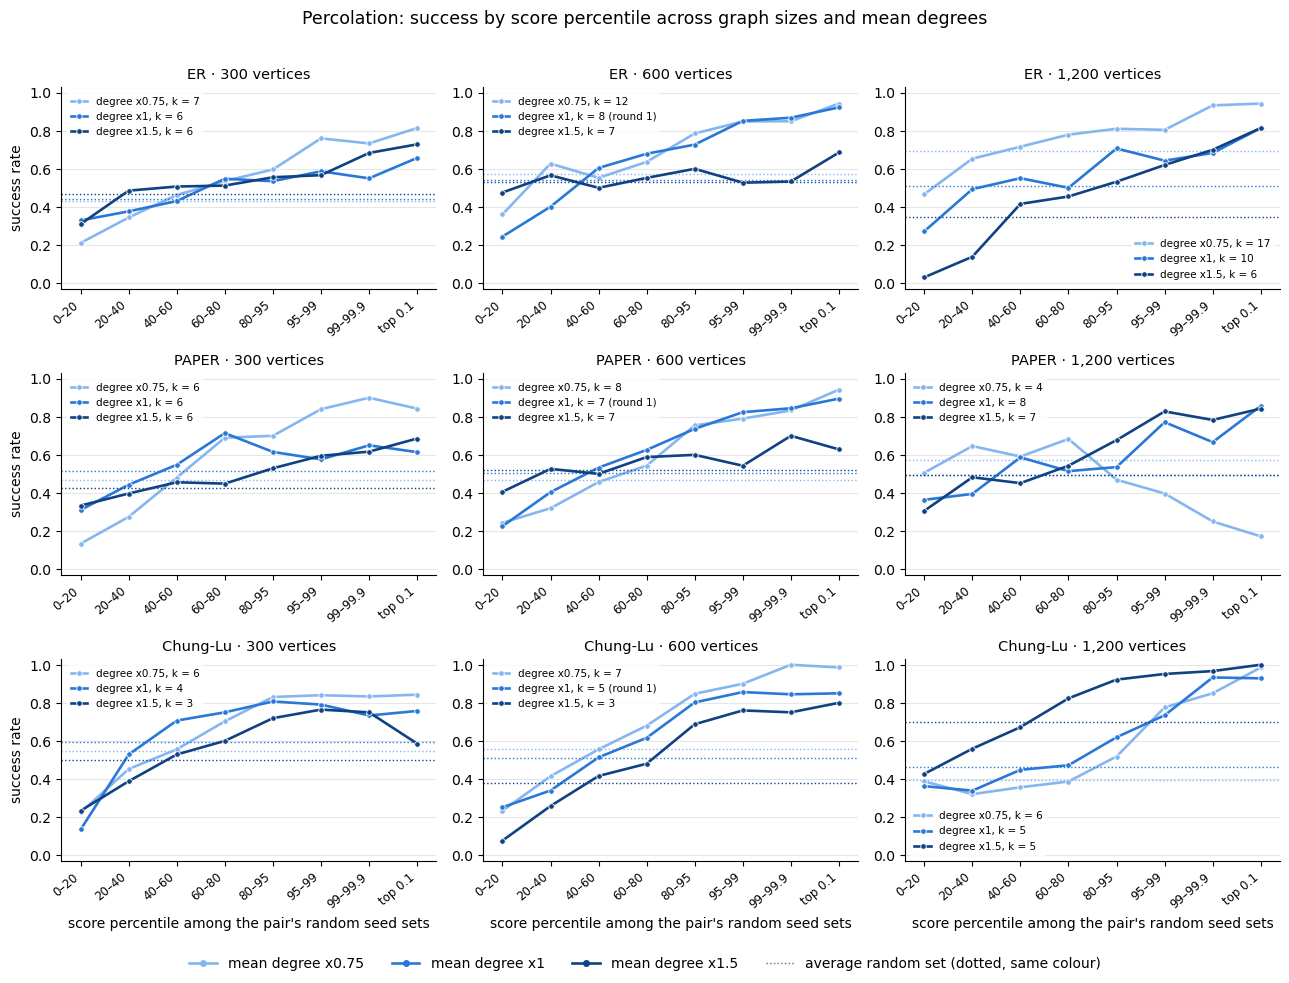

In [23]:
if (data['part'] == 'C').any():
    for algorithm in [a for a in ST.ALGORITHMS if a in set(data.loc[data['part'] == 'C', 'algorithm'])]:
        ST.plot_grid(curves, algorithm)
        plt.show()
else:
    print('Part C has no results yet.')

### 4.2 Ranking and lift across the grid

- **Figure:** the score's AUC on each cell's random sets as solid lines, and degree alone as dashed lines, against mean degree. There is one colour per graph size, and the 600-vertex, × 1 point is part A. The vertical lines on the solid lines are 95% intervals over pairs.
- **Tables:** the same numbers with intervals, and the success of the random and top-scoring sets in each cell (as in section 2.1).

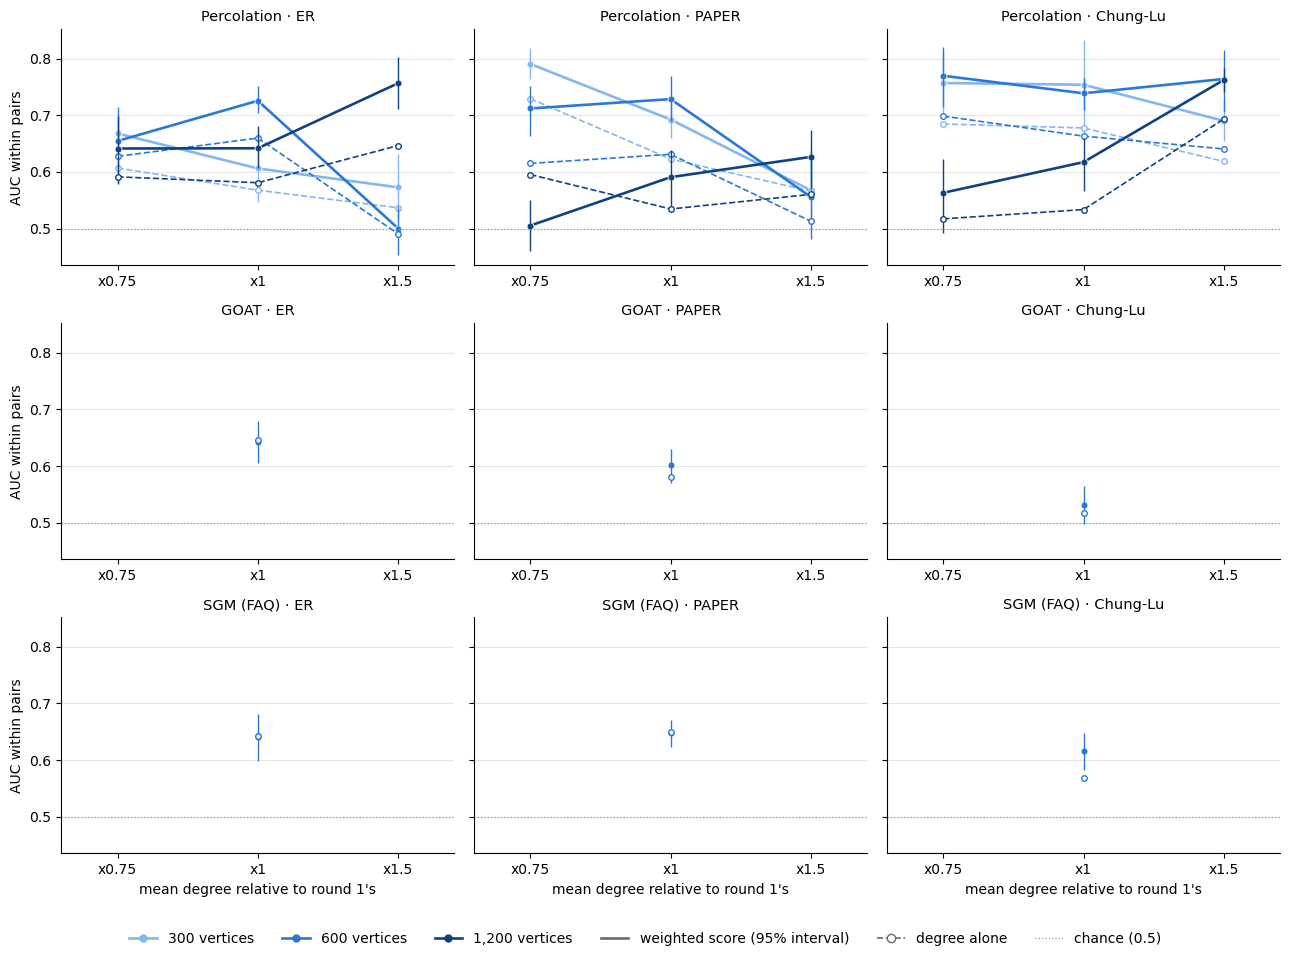

pairs             random  \
algorithm   model    condition   budget                             
Percolation ER       n300_x0.75  7          10  0.43 [0.39, 0.48]   
                     n300_x1     6          10  0.44 [0.39, 0.48]   
                     n300_x1.5   6          10  0.47 [0.39, 0.53]   
                     n600_x0.75  12         10  0.57 [0.54, 0.61]   
                     n600_x1.5   7          10  0.53 [0.47, 0.59]   
                     n1200_x0.75 17         10  0.69 [0.63, 0.76]   
                     n1200_x1    10         10  0.51 [0.44, 0.58]   
                     n1200_x1.5  6          10  0.34 [0.29, 0.39]   
            PAPER    n300_x0.75  6          10  0.47 [0.40, 0.52]   
                     n300_x1     6          10  0.52 [0.45, 0.59]   
                     n300_x1.5   6          10  0.43 [0.38, 0.48]   
                     n600_x0.75  8          10  0.47 [0.40, 0.53]   
                     n600_x1.5   7          10  0.52 [0.41, 0.63]   
                     n1200_x0.75 4          10  0.57 [0.51, 0.62]   
                     n1200_x1    8          10  0.49 [0.44, 0.55]   
                     n1200_x1.5  7          10  0.49 [0.42, 0.56]   
            Chung-Lu n300_x0.75  6          10  0.55 [0.51, 0.60]   
                     n300_x1     4          10  0.59 [0.56, 0.63]   
                     n300_x1.5   3          10  0.50 [0.44, 0.55]   
                     n600_x0.75  7          10  0.56 [0.50, 0.61]   
                     n600_x1.5   3          10  0.38 [0.32, 0.43]   
                     n1200_x0.75 6          10  0.39 [0.35, 0.43]   
                     n1200_x1    5          10  0.46 [0.41, 0.51]   
                     n1200_x1.5  5          10  0.70 [0.66, 0.73]   

                                                tail 95-99  \
algorithm   model    condition   budget                      
Percolation ER       n300_x0.75  7       0.79 [0.71, 0.87]   
                     n300_x1     6       0.59 [0.47, 0.71]   
                     n300_x1.5   6       0.59 [0.51, 0.67]   
                     n600_x0.75  12      0.84 [0.78, 0.90]   
                     n600_x1.5   7       0.54 [0.46, 0.62]   
                     n1200_x0.75 17      0.81 [0.74, 0.88]   
                     n1200_x1    10      0.63 [0.55, 0.72]   
                     n1200_x1.5  6       0.62 [0.55, 0.69]   
            PAPER    n300_x0.75  6       0.84 [0.78, 0.91]   
                     n300_x1     6       0.57 [0.45, 0.67]   
                     n300_x1.5   6       0.61 [0.52, 0.71]   
                     n600_x0.75  8       0.78 [0.72, 0.85]   
                     n600_x1.5   7       0.56 [0.42, 0.71]   
                     n1200_x0.75 4       0.39 [0.29, 0.49]   
                     n1200_x1    8       0.77 [0.68, 0.85]   
                     n1200_x1.5  7       0.87 [0.81, 0.93]   
            Chung-Lu n300_x0.75  6       0.83 [0.74, 0.93]   
                     n300_x1     4       0.79 [0.74, 0.85]   
                     n300_x1.5   3       0.77 [0.72, 0.82]   
                     n600_x0.75  7       0.91 [0.88, 0.94]   
                     n600_x1.5   3       0.76 [0.68, 0.83]   
                     n1200_x0.75 6       0.77 [0.68, 0.85]   
                     n1200_x1    5       0.76 [0.66, 0.83]   
                     n1200_x1.5  5       0.95 [0.92, 0.97]   

                                          tail 95-99 - random  \
algorithm   model    condition   budget                         
Percolation ER       n300_x0.75  7       +0.36 [+0.29, +0.44]   
                     n300_x1     6       +0.15 [+0.06, +0.25]   
                     n300_x1.5   6       +0.12 [+0.03, +0.22]   
                     n600_x0.75  12      +0.27 [+0.20, +0.34]   
                     n600_x1.5   7       +0.01 [-0.06, +0.09]   
                     n1200_x0.75 17      +0.11 [+0.07, +0.17]   
                     n1200_x1    10      +0.12 [+0.02, +0.22]   
                     n1200_x1.5  6       +0.27 [

random success  \
algorithm   model    condition   budget                   
Percolation ER       n300_x0.75  7                 0.43   
                     n300_x1     6                 0.44   
                     n300_x1.5   6                 0.47   
                     n600_x0.75  12                0.57   
                     n600_x1.5   7                 0.53   
                     n1200_x0.75 17                0.69   
                     n1200_x1    10                0.51   
                     n1200_x1.5  6                 0.34   
            PAPER    n300_x0.75  6                 0.47   
                     n300_x1     6                 0.52   
                     n300_x1.5   6                 0.43   
                     n600_x0.75  8                 0.47   
                     n600_x1.5   7                 0.52   
                     n1200_x0.75 4                 0.57   
                     n1200_x1    8                 0.49   
                     n1200_x1.5  7                 0.49   
            Chung-Lu n300_x0.75  6                 0.55   
                     n300_x1     4                 0.59   
                     n300_x1.5   3                 0.50   
                     n600_x0.75  7                 0.56   
                     n600_x1.5   3                 0.38   
                     n1200_x0.75 6                 0.39   
                     n1200_x1    5                 0.46   
                     n1200_x1.5  5                 0.70   

                                         pairs with both outcomes  \
algorithm   model    condition   budget                             
Percolation ER       n300_x0.75  7                             10   
                     n300_x1     6                             10   
                     n300_x1.5   6                             10   
                     n600_x0.75  12                            10   
                     n600_x1.5   7                             10   
                     n1200_x0.75 17                            10   
                     n1200_x1    10                            10   
                     n1200_x1.5  6                             10   
            PAPER    n300_x0.75  6                             10   
                     n300_x1     6                             10   
                     n300_x1.5   6                             10   
                     n600_x0.75  8                             10   
                     n600_x1.5   7                             10   
                     n1200_x0.75 4                             10   
                     n1200_x1    8                             10   
                     n1200_x1.5  7                             10   
            Chung-Lu n300_x0.75  6                             10   
                     n300_x1     4                             10   
                     n300_x1.5   3                             10   
                     n600_x0.75  7                             10   
                     n600_x1.5   3                             10   
                     n1200_x0.75 6                             10   
                     n1200_x1    5                             10   
                     n1200_x1.5  5                             10   

                                                 AUC score         AUC degree  \
algorithm   model    condition   budget                                         
Percolation ER       n300_x0.75  7       0.67 [0.64, 0.70]  0.61 [0.55, 0.66]   
                     n300_x1     6       0.61 [0.55, 0.66]  0.57 [0.52, 0.62]   
                     n300_x1.5   6       0.57 [0.52, 0.63]  0.54 [0.44, 0.62]   
                     n600_x0.75  12      0.65 [0.58, 0.71]  0.63 [0.58, 0.67]   
                     n600_x1.5   7       0.50 [0.45, 0.54]  0.49 [0.45, 0.52]   
                     n1200_x0.75 17      0.64 [0.58, 0.70]  0.59 [0.55, 0.63]   
                     n1200_x1    10      0.64 [0.61, 0.68]  0.5

In [24]:
if (data['part'] == 'C').any():
    ST.plot_grid_auc(ranking)
    plt.show()
    display(lifts.xs('C', level='part'))
    display(ST.show_ranking(ranking[ranking['part'] == 'C']).droplevel('part'))

## 5. Ranking at the training setting and other budgets

Each row is one setting and budget (parts A and B; part C has its own figure in section 4.2).
- **Filled dot:** the score's AUC.
- **Open dot:** degree alone.
- **Whiskers:** 95% intervals over pairs.
- **Grey filled dot:** the score's held-out AUC on the multi-pair data.

Further right means better ranking, and 0.5 (dashed) is chance. Where the filled dot is right of the open one, the extra features help beyond degree. If the score keeps its AUC at other budgets, the weights generalise across budgets.

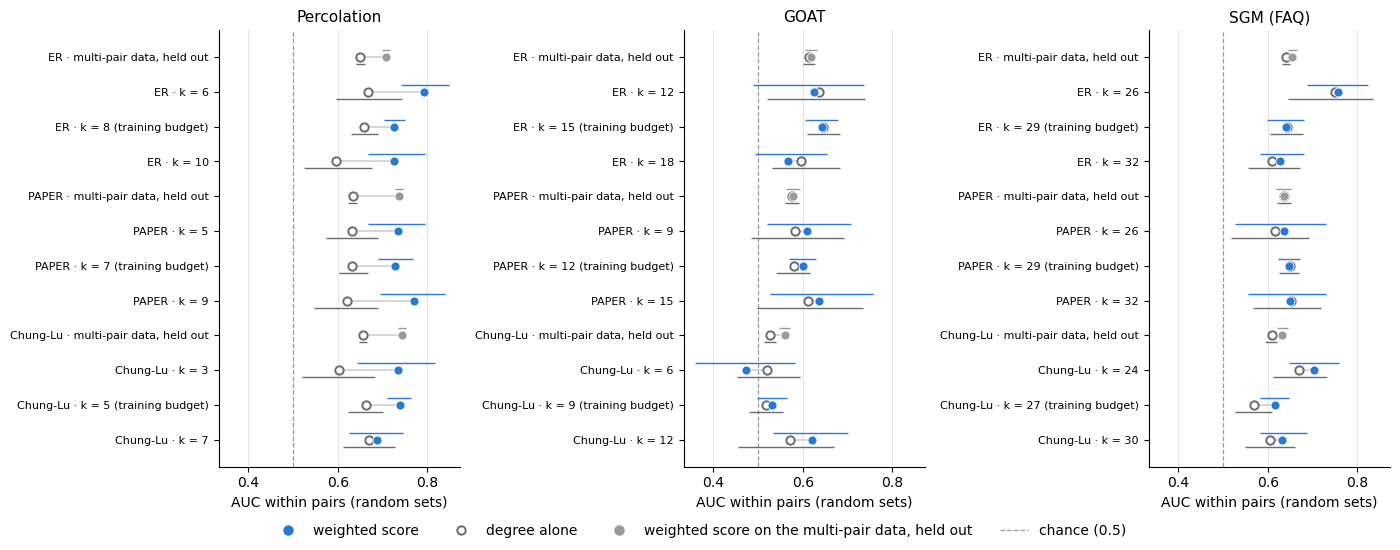

In [25]:
ST.plot_auc(ranking, reference_auc)
plt.show()

## 6. GOAT runs that stall

GOAT runs that stop within 3 iterations have stalled: the transport step barely moves, as seen at r = 100 in the temperature audit. Stalled runs almost never succeed, so a high stall share means the labels reflect the solver more than the seeds. All runs here use round 1's regulariser (ER 100, PAPER 300, Chung–Lu 300).

In [26]:
stalls = ST.stall_table(data)
display(stalls if not stalls.empty else 'No GOAT runs yet.')

runs  stalled share  \
part model    condition budget                        
A    ER       training  15      2100          0.000   
     PAPER    training  12      2100          0.000   
     Chung-Lu training  9       2100          0.001   
B    ER       k0-3      12       600          0.000   
              k0+3      18       600          0.000   
     PAPER    k0-3      9        600          0.005   
              k0+3      15       600          0.000   
     Chung-Lu k0-3      6        600          0.013   
              k0+3      12       600          0.000   

                                stalled share, random sets  \
part model    condition budget                               
A    ER       training  15                           0.000   
     PAPER    training  12                           0.000   
     Chung-Lu training  9                            0.002   
B    ER       k0-3      12                           0.000   
              k0+3      18                           0.000   
     PAPER    k0-3      9                            0.000   
              k0+3      15                           0.000   
     Chung-Lu k0-3      6                            0.011   
              k0+3      12                           0.000   

                                stalled share, tail sets  \
part model    condition budget                             
A    ER       training  15                         0.000   
     PAPER    training  12                         0.000   
     Chung-Lu training  9                          0.001   
B    ER       k0-3      12                         0.000   
              k0+3      18                         0.000   
     PAPER    k0-3      9                          0.013   
              k0+3      15                         0.000   
     Chung-Lu k0-3      6                          0.017   
              k0+3      12                         0.000   

                                success when stalled  median iterations  
part model    condition budget                                           
A    ER       training  15                       NaN               25.0  
     PAPER    training  12                       NaN               22.0  
     Chung-Lu training  9                        0.0               33.0  
B    ER       k0-3      12                       NaN               45.0  
              k0+3      18                       NaN               12.0  
     PAPER    k0-3      9                        0.0               41.0  
              k0+3      15                       NaN               13.0  
     Chung-Lu k0-3      6                        0.0               45.0  
              k0+3      12                       NaN               16.0